# ML6: Implement K-Means clustering / hierarchical clustering on
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;sales\_data\_sample.csv dataset. Determine the number of clusters using  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;the elbow method.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Dataset: https://www.kaggle.com/datasets/kyanyoga/sample-sales-data  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(download "sales\_data\_sample.csv" and keep it in the same folder)  

## Theory

### 1. UNSUPERVISED LEARNING / CLUSTERING (Unit V)
&nbsp;&nbsp;&nbsp;No target labels. CLUSTERING groups data so that points in the same  
&nbsp;&nbsp;&nbsp;cluster are similar (high intra-cluster similarity) and points in different  
&nbsp;&nbsp;&nbsp;clusters are dissimilar (low inter-cluster similarity).  
&nbsp;&nbsp;&nbsp;Applications: customer segmentation, market basket analysis, image  
&nbsp;&nbsp;&nbsp;segmentation, anomaly detection.  

### 2. K-MEANS ALGORITHM (partitioning, centroid based)
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;1. Choose k; initialise k centroids (randomly / k-means++).  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;2. ASSIGN each point to the nearest centroid (Euclidean distance).  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3. UPDATE each centroid = mean of points assigned to it.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4. Repeat 2-3 until centroids do not change (convergence).  
&nbsp;&nbsp;&nbsp;Objective: minimise WCSS / inertia = SUM\_k SUM\_{x in C\_k} ||x - mu\_k||^2.  
&nbsp;&nbsp;&nbsp;Time O(n k d t). Sensitive to initialisation, outliers and scale; assumes  
&nbsp;&nbsp;&nbsp;spherical clusters; k must be given.  
&nbsp;&nbsp;&nbsp;K-MEDOIDS (PAM): uses actual data points (medoids) as centres -&gt; robust to  
&nbsp;&nbsp;&nbsp;outliers.  

### 3. ELBOW METHOD
&nbsp;&nbsp;&nbsp;Run K-means for k = 1..10 and plot WCSS vs k. WCSS always decreases as k  
&nbsp;&nbsp;&nbsp;increases; the point where the decrease sharply slows down ("elbow") is  
&nbsp;&nbsp;&nbsp;chosen as the optimal k. (Here also detected automatically using maximum  
&nbsp;&nbsp;&nbsp;distance from the line joining first and last points.)  
&nbsp;&nbsp;&nbsp;Other intrinsic measures: SILHOUETTE coefficient s = (b - a)/max(a, b),  
&nbsp;&nbsp;&nbsp;in [-1, 1] (a = mean intra-cluster distance, b = mean nearest-cluster  
&nbsp;&nbsp;&nbsp;distance); Davies-Bouldin index. EXTRINSIC measures (need ground truth):  
&nbsp;&nbsp;&nbsp;purity, Rand index, NMI.  

### 4. HIERARCHICAL CLUSTERING
&nbsp;&nbsp;&nbsp;Builds a tree of clusters (DENDROGRAM).  
&nbsp;&nbsp;&nbsp;- AGGLOMERATIVE (bottom-up): start with each point as a cluster, merge the  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;two closest clusters repeatedly.  
&nbsp;&nbsp;&nbsp;- DIVISIVE (top-down): start with one cluster, split recursively.  
&nbsp;&nbsp;&nbsp;Linkage (distance between clusters): single (min), complete (max),  
&nbsp;&nbsp;&nbsp;average, WARD (minimum increase in variance).  
&nbsp;&nbsp;&nbsp;No need to fix k in advance - cut the dendrogram at a height. O(n^2) memory.  

### 5. OTHER CLUSTERING (syllabus)
&nbsp;&nbsp;&nbsp;- DBSCAN (density based): eps radius &amp; minPts; finds arbitrary shapes and  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;labels noise points; no k needed.  
&nbsp;&nbsp;&nbsp;- Spectral clustering: uses eigenvectors of a similarity graph Laplacian.  

### 6. PRE-PROCESSING HERE
&nbsp;&nbsp;&nbsp;Numeric features QUANTITYORDERED, PRICEEACH, SALES, MSRP (+ encoded  
&nbsp;&nbsp;&nbsp;DEALSIZE) are selected and STANDARDIZED because K-means is distance based.  

### Conclusion
The elbow curve shows the optimal number of clusters (about 3),
and both K-means and agglomerative clustering segment the sales orders into  
groups such as small / medium / large deals.

In [1]:
%matplotlib inline

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

DATA = "sales_data_sample.csv"   # CSV file kept next to this notebook

### 1. Read & pre-process

In [3]:
df = pd.read_csv(DATA, encoding="latin1")      # file is not UTF-8
print("Shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

features = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
data = df[features].copy()
if "DEALSIZE" in df.columns:
    data["DEALSIZE"] = df["DEALSIZE"].map({"Small": 0, "Medium": 1,
                                           "Large": 2})
data = data.dropna()
print("\nFeatures used:", list(data.columns))

X = StandardScaler().fit_transform(data)

Shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Ab

### 2. Elbow method

k =  1  WCSS = 14115.00


k =  2  WCSS = 7601.15


k =  3  WCSS = 6022.65
k =  4  WCSS = 4768.59


k =  5  WCSS = 3790.37
k =  6  WCSS = 3298.29


k =  7  WCSS = 2865.13
k =  8  WCSS = 2553.23


k =  9  WCSS = 2333.45
k = 10  WCSS = 2187.03

Optimal number of clusters (elbow) = 3


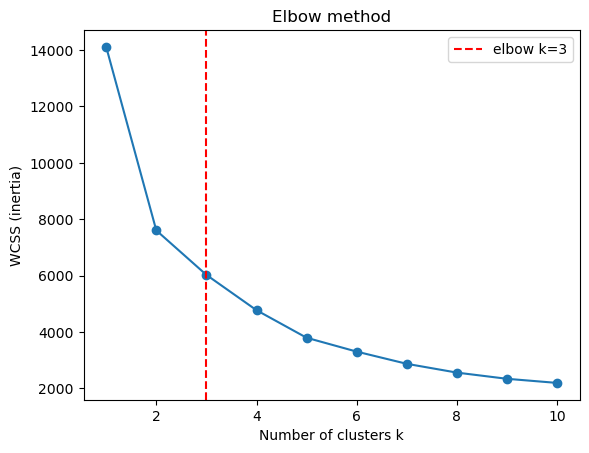

In [4]:
wcss = []
K = range(1, 11)
for k in K:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X)
    wcss.append(km.inertia_)
    print(f"k = {k:2d}  WCSS = {km.inertia_:.2f}")

# automatic elbow: point farthest from line joining first & last WCSS points
p1, p2 = np.array([1, wcss[0]]), np.array([10, wcss[-1]])
d = p2 - p1
dists = [abs(d[0] * (p1[1] - w) - d[1] * (p1[0] - k)) / np.linalg.norm(d)
         for k, w in zip(K, wcss)]
best_k = list(K)[int(np.argmax(dists))]
print("\nOptimal number of clusters (elbow) =", best_k)

plt.plot(list(K), wcss, marker="o")
plt.axvline(best_k, color="r", linestyle="--", label=f"elbow k={best_k}")
plt.xlabel("Number of clusters k")
plt.ylabel("WCSS (inertia)")
plt.title("Elbow method")
plt.legend()
plt.show()

### 3. K-Means with optimal k


K-Means silhouette score = 0.3300
Cluster sizes:
 KMeans_Cluster
0     917
1    1095
2     811
Name: count, dtype: int64

Cluster profile (mean of features):
                QUANTITYORDERED  PRICEEACH    SALES    MSRP
KMeans_Cluster                                             
0                         33.64      58.40  1942.79   64.55
1                         42.79      95.36  5278.10  120.08
2                         26.34      96.42  3047.55  115.47


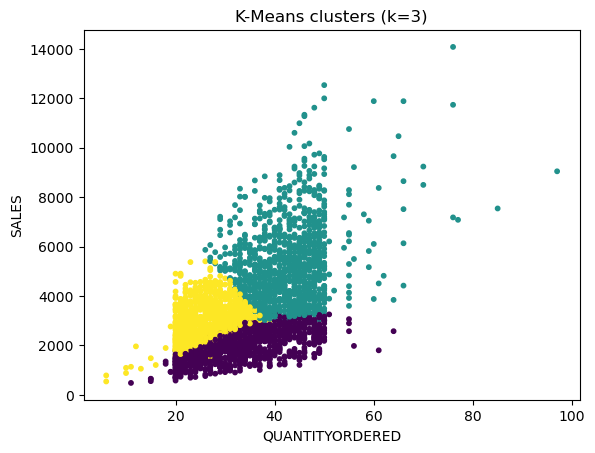

In [5]:
kmeans = KMeans(n_clusters=best_k, init="k-means++", n_init=10,
                random_state=42)
data["KMeans_Cluster"] = kmeans.fit_predict(X)
print(f"\nK-Means silhouette score = "
      f"{silhouette_score(X, data['KMeans_Cluster']):.4f}")
print("Cluster sizes:\n", data["KMeans_Cluster"].value_counts().sort_index())
print("\nCluster profile (mean of features):")
print(data.groupby("KMeans_Cluster")[features].mean().round(2))

plt.scatter(data["QUANTITYORDERED"], data["SALES"],
            c=data["KMeans_Cluster"], cmap="viridis", s=10)
plt.xlabel("QUANTITYORDERED")
plt.ylabel("SALES")
plt.title(f"K-Means clusters (k={best_k})")
plt.show()

### 4. Hierarchical (agglomerative) clustering

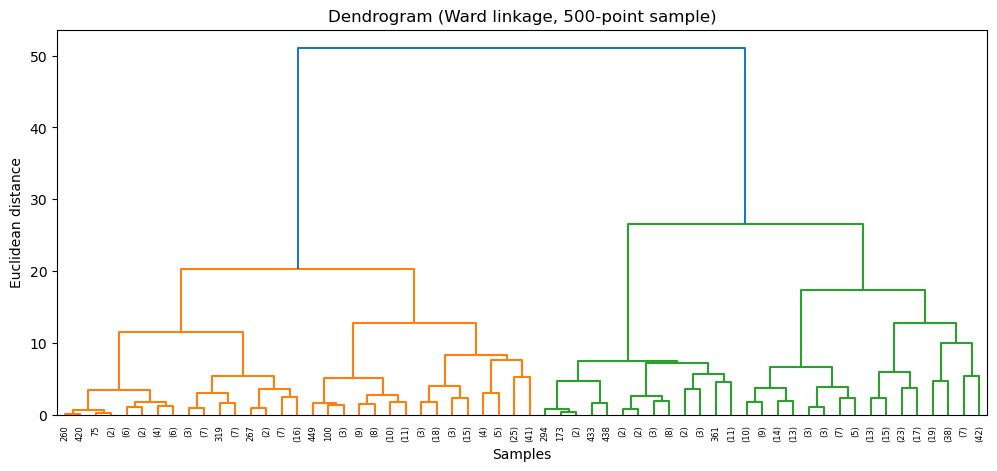


Hierarchical silhouette score = 0.4009
Cluster sizes:
 Hier_Cluster
0    1294
1    1372
2     157
Name: count, dtype: int64


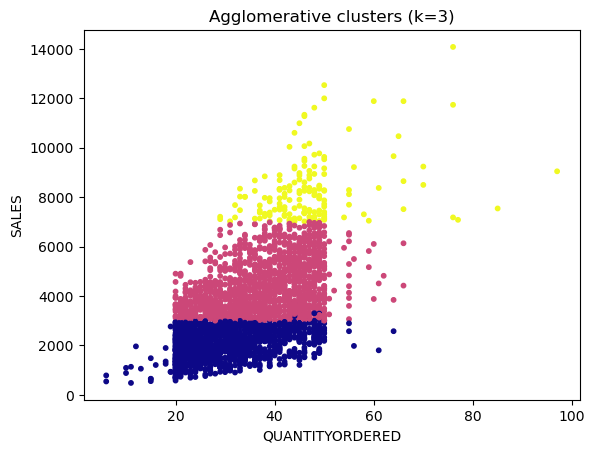

In [6]:
sample = X[np.random.RandomState(42).choice(len(X), min(500, len(X)),
                                            replace=False)]
plt.figure(figsize=(12, 5))
dendrogram(linkage(sample, method="ward"), truncate_mode="level", p=5)
plt.title("Dendrogram (Ward linkage, 500-point sample)")
plt.xlabel("Samples")
plt.ylabel("Euclidean distance")
plt.show()

agg = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
data["Hier_Cluster"] = agg.fit_predict(X)
print(f"\nHierarchical silhouette score = "
      f"{silhouette_score(X, data['Hier_Cluster']):.4f}")
print("Cluster sizes:\n", data["Hier_Cluster"].value_counts().sort_index())

plt.scatter(data["QUANTITYORDERED"], data["SALES"],
            c=data["Hier_Cluster"], cmap="plasma", s=10)
plt.xlabel("QUANTITYORDERED")
plt.ylabel("SALES")
plt.title(f"Agglomerative clusters (k={best_k})")
plt.show()